# 4 · Beyond the Js: moment of inertia, Love numbers, differential rotation

**Covered topics:** the other quantities PyToF computes for a relaxed model - the normalized moment of inertia and the tidal Love function — and how to include differential rotation (zonal winds) in the shape calculation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

from PyToF import ToF
from tutorial_utils import JUPITER_RADIUS, LABELS, jupiter
import references

plt.rcParams["figure.figsize"] = (5.2, 3.9)  # smaller default figures

## Normalized moment of inertia

`X.get_NMoI()` returns $I / (M\,l_\mathrm{max}^2)$, the polar moment of inertia of the relaxed model normalized with the mass and the squared mean radius of the outermost level surface. It integrates the density over the *oblate* level surfaces, so it includes the effect of rotation. Sanity checks with simple bodies (a sphere has $2/5$ for constant density and $4/15$ for a density that falls linearly from the centre to zero at the surface; the remaining difference to the exact value is the grid, which ends at $10^{-3}R$ instead of $0$):

In [2]:
N = 1024
radius = 1e6
radii = radius * np.linspace(1, 1e-3, N)

for name, dens, exact in [("constant density", np.ones(N), 2 / 5), ("linear density", np.linspace(0, 1, N), 4 / 15)]:
    dens = 1000 * dens
    mass = -4 * np.pi * trapezoid(dens * radii**2, radii)
    X = ToF(N=N, M_phys=mass, R_phys=[radius, "mean"], Period=np.inf, R_ref=radius)
    X.li, X.rhoi, X.m_rot_calc = radii, dens, 0.0
    X.relax_to_shape()
    print(f"{name:17s} PyToF {X.get_NMoI():.6f}   exact {exact:.6f}")

constant density  PyToF 0.400000   exact 0.400000
linear density    PyToF 0.266667   exact 0.266667


For giant planets the moment of inertia is not measured directly, but it is one of the things an interior model predicts, and it is correlated with $J_2$: models that fit the same $J_2$ can still differ in $I$. A one-parameter family of Jupiter models (the polytropic index $n$ of notebook 2) already traces out a curve:

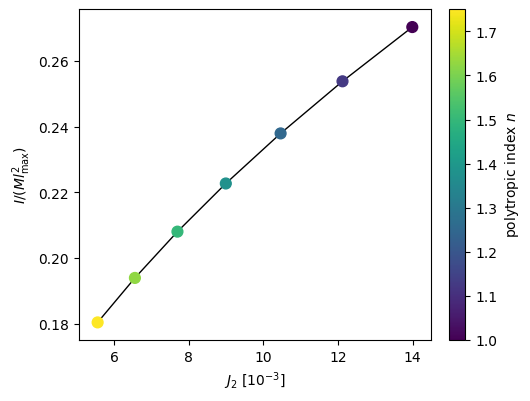

In [3]:
J2s, nmois = [], []
indices = np.linspace(1.0, 1.75, 7)
for n in indices:
    Y = ToF(N=512, order=4, R_ref=JUPITER_RADIUS, baro_param=[n])
    Y.set_barotrope(lambda P, param: P ** (param[0] / (param[0] + 1)))
    Y.relax_to_barotrope()
    J2s.append(Y.Js[1])
    nmois.append(Y.get_NMoI())

fig, ax = plt.subplots(layout="constrained")
sc = ax.scatter(np.array(J2s) * 1e3, nmois, c=indices, cmap="viridis", s=60, zorder=3)
ax.plot(np.array(J2s) * 1e3, nmois, "k-", linewidth=1, zorder=2)
ax.set_xlabel(r"$J_2$ [$10^{-3}$]")
ax.set_ylabel(r"$I / (M l_\mathrm{max}^2)$")
ax.margins(0.06)
fig.colorbar(sc, ax=ax, label="polytropic index $n$");

`get_NMoI(N=1000)` integrates numerically over `N` values of $\mu$; the default is converged to better than $10^{-8}$ for typical models.

## Love numbers

`X.get_Kn(n)` solves the perturbation equation for the response of the planet to a tidal potential of degree $n \geq 2$ and returns three arrays: the radius `r`, the function $T_n(r)$ and the **Love function** $K_n(r)$. The value at the surface, `K[-1]`, is the Love number $k_n$. For $n=2$ and a non-rotating planet the result can be checked against the analytical value of a polytrope of index 1, $k_2 = 15/\pi^2 - 1 \approx 0.5198$ (Gavrilov et al. 1976; more analytical profiles are checked in `accuracy/accuracy_quick.ipynb`):

In [4]:
nonrotating = jupiter(N=1024, order=4, Period=1e12)
r, T2, K2 = nonrotating.get_Kn(2)
print(f"non-rotating: k_2 = {K2[-1]:.5f}   analytical: {15 / np.pi**2 - 1:.5f}")

X = jupiter(N=1024, order=4)  # Jupiter's rotation
r, T2, K2 = X.get_Kn(2)
print(f"Jupiter-like rotation: k_2 = {K2[-1]:.5f}")

non-rotating: k_2 = 0.51982   analytical: 0.51982


Jupiter-like rotation: k_2 = 0.55706


The rotation of the planet is included in the structure (through the potential $U$ of the relaxed model), so the Love number of the rotating model is different, here by about 7%. The functions for several degrees:

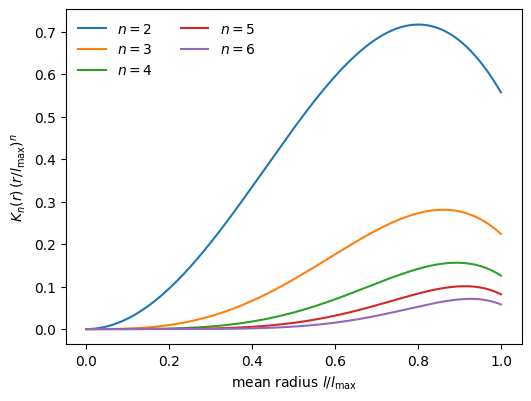

In [5]:
fig, ax = plt.subplots(layout="constrained")
for n in range(2, 7):
    r, T, K = X.get_Kn(n)
    ax.plot(r / X.li[0], K * (r / X.li[0]) ** n, label=f"$n = {n}$")
ax.set_xlabel(LABELS["r"])
ax.set_ylabel(r"$K_n(r)\,(r/l_\mathrm{max})^n$")
ax.legend(frameon=False, ncol=2);

**Density jumps.** At a density discontinuity the derivative of the density is infinite, and the solution of the perturbation equation has to be continued across the jump with a boundary condition. You have to tell `get_Kn` where the discontinuities are, via `bs`, the list of radii (in m, the same units as `X.li`). A planet with a dense core inside half of its radius:

In [6]:
radius, period = 1e6, 24 * 3600
dens_core = np.where(radii < 0.5 * radius, 3000.0, 1000.0)
mass_core = -4 * np.pi * trapezoid(dens_core * radii**2, radii)

C = ToF(N=N, order=4, M_phys=mass_core, R_phys=[radius, "mean"], Period=period, R_ref=radius, verbosity=2)
C.li, C.rhoi = radii, dens_core
C.m_rot_calc = (2 * np.pi / period) ** 2 * C.li[0] ** 3 / (C.opts["G"] * mass_core)
C.relax_to_shape()

_, _, K_wrong = C.get_Kn(2)  # without telling PyToF about the jump
_, _, K_right = C.get_Kn(2, bs=[0.5 * radius])
print(f"k_2 ignoring the jump: {K_wrong[-1]:.4f}   with bs=[0.5 R]: {K_right[-1]:.4f}")

/home/lumo/Code/PyToF_dev/PyToF/AlgoToF.py:539: AccuracyWarning: Reverting to the more stable and less accurate trapezoid rule for integration because S_0, itself proportional to the enclosed mass function, has become non-monotonic. Discontinuities in the density gradient due to jumps in density are likely responsible.
  warn_simpson_fallback(


Relaxing to shape finished after 40 iterations: dJ = 9.7e-11.
Relaxing to shape done in 5.54e-02 seconds.
Boundary condition applied at a radius of r/R=0.50 with a density jump of 2.00e+03 kg/m^3.


k_2 ignoring the jump: 0.0209   with bs=[0.5 R]: 0.1265


`bs` is matched to the closest grid point, so the grid should resolve the jump (one grid step). With `verbosity>=2` PyToF reports the boundary condition it applied and the size of the density jump it found.

## Differential rotation

Zonal winds on the giant planets mean that the planet does not rotate as a solid body. If the rotation rate depends only on the distance $s$ from the rotation axis (*barotropic* differential rotation), the hydrostatic problem remains a Theory of Figures problem with a modified centrifugal potential. In PyToF the deviation from solid body rotation is the option `alphas`, an array of 12 coefficients in m² s⁻² of a polynomial in the squared distance from the rotation axis (the exact definition is in Wisdom & Hubbard 2016 and Appendix A of Morf et al. 2024). Values of order $10^5$ m² s⁻² are typical; much smaller values have no visible effect. The default is solid body rotation, all zeros.

As an example we use the zonal wind profile "DR2" of Wisdom & Hubbard (2016), a four-parameter fit for Jupiter, stored in `accuracy/references.py`:

In [7]:
alphas_dr2 = references.alphas_array(references.ALPHAS_DR2)
print("alphas [m^2/s^2]:", alphas_dr2[:5])

solid = jupiter(N=2048, order=7)
diff_rot = jupiter(N=2048, order=7, alphas=alphas_dr2)

print(f"{'':6s}{'solid body':>14s}{'with DR2':>14s}{'CMS, DR2':>14s}{'PyToF vs CMS':>14s}")
for n in range(1, 5):
    ref = references.CMSDR2[n]
    print(f"J_{2 * n:<4d}{solid.Js[n]:14.6e}{diff_rot.Js[n]:14.6e}{ref:14.6e}{abs(diff_rot.Js[n] / ref - 1):14.1e}")

alphas [m^2/s^2]: [  -58954.16643192   461233.89620923 -1042664.27700998   830306.3645313
        0.        ]


          solid body      with DR2      CMS, DR2  PyToF vs CMS
J_2     1.398851e-02  1.399612e-02  1.399686e-02       5.3e-05
J_4    -5.318280e-04 -5.357559e-04 -5.358081e-04       9.7e-05
J_6     3.011841e-05  3.158702e-05  3.159101e-05       1.3e-04
J_8    -2.131913e-06 -2.625551e-06 -2.626581e-06       3.9e-04


The last column compares with the Concentric Maclaurin Spheroid (CMS) calculation of Wisdom & Hubbard (2016), an independent method: the two agree to $10^{-4}$ or better for $J_2$ to $J_6$, much less than the effect of the winds themselves, which changes $J_2$ by $5\times10^{-4}$, $J_4$ by 0.7%, $J_6$ by 5% and $J_8$ by 23% relative to solid body rotation. Such large effects on the higher moments are why gravity measurements can constrain the depth of the winds.

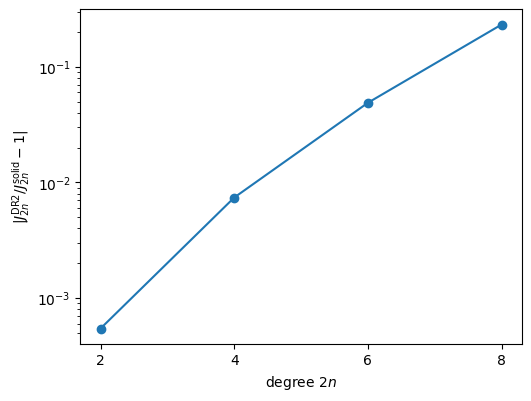

In [8]:
n = np.arange(1, 5)
fig, ax = plt.subplots(layout="constrained")
ax.plot(2 * n, np.abs(diff_rot.Js[1:5] / solid.Js[1:5] - 1), "o-")
ax.set_yscale("log")
ax.set_xlabel("degree $2n$")
ax.set_ylabel(r"$|J_{2n}^\mathrm{DR2} / J_{2n}^\mathrm{solid} - 1|$")
ax.set_xticks(2 * n);

A caveat: for differential rotation PyToF has **no error estimates**. The tables behind `get_Js_errors()` exist only for solid body rotation, and the function says so:

In [9]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    diff_rot.get_Js_errors()
print(caught[0].message)

Accuracy when using differential rotation is unknown. PyToF provides no error estimates.


The agreement with the CMS method was checked for two wind profiles (DR2 above and a ten-parameter DR3), see `accuracy/accuracy_full.ipynb`.

## What else is in the object

* `X.U[i]` is the total potential (gravity plus centrifugal) on the level surface $i$ in m² s⁻², with the sign convention of notebook 1 (positive, growing towards the centre); it is constant on a level surface by construction, so one number per surface. The pressure follows from hydrostatic equilibrium, $\mathrm{d}P = \rho\,\mathrm{d}U$, which is how `X.Pi` is obtained.
* `X.get_U_l_mu(mu)` evaluates the potential on the level surfaces as a function of $\mu$ (identical for all $\mu$ up to rounding, a good consistency check).
* `X.volume_integrals`, `X.A0` are intermediate results of the Theory of Figures (Appendix A of Morf et al. 2024).

## Takeaways

* `get_NMoI()` for the moment of inertia, `get_Kn(n, bs=...)` for Love functions (tell it where the density jumps are).
* `alphas` switches on barotropic differential rotation; PyToF agrees with the CMS method, but gives no error estimates.

Next: [5 · numerics guide](05_numerics_guide.ipynb).